# Samuel — Independent EDA Discovery TP2

**A06 KasdudLovers · SamuelIndriano · 31 Oktober 2026 · comparative research untuk review**

Tujuan saya adalah menilai apakah ada pertanyaan EDA pengganti yang lebih fokus dan mudah
dijelaskan, tanpa menganggap EDA lama lemah. Enam arah diperiksa dengan data, lalu A (keragaman
token), C (availability), dan F (keselarasan outcome) diinvestigasi lebih dalam.
**Rekomendasi: A**, dengan cakupan dan counterexample di bawah. Pertanyaan resmi belum diganti.

Tidak ada modeling atau Kaggle submission dalam notebook ini. Keberhasilan model sebelumnya
hanya menjadi konteks hipotesis; semua bukti baru dihitung melalui EDA tersendiri.

## Data dan rancangan

PDF resmi TP2 (57 halaman, SHA awal `386fa635…`) mewajibkan pertanyaan EDA individual,
eksplorasi, visualisasi, dan interpretasi (p.2); tidak mewajibkan metode canggih tertentu.
`signal_stream` adalah token teknis anonim, dapat kosong/noisy (p.16); `text_load`
adalah indikator volume narasi (p.17). Makna target TP2 dan metrik berasal dari konfirmasi
kompetisi di `docs/COMPETITION_INFO.md`, bukan formula target yang ditebak dari data.

Gunakan Python/dependensi dalam `requirements.txt`, serta kedua official Train di
`data/raw/{regression,classification}/Train.csv`, atau `TP2_DATA_DIR` ke folder induknya.
Test, cache eksperimen, file sementara, dan kredensial tidak dibutuhkan.
Notebook ini menjalankan ulang empat skrip analisis dari data mentah dan menyimpan
tabel/grafik agregat hanya di `reports/eda_candidates/`.

Semua Train telah dilihat pada riset sebelumnya. Bins, support rules, dan kandidat dipilih
dalam discovery; ini **eksploratif**, bukan praregistrasi atau validasi konfirmatori independen.
Tidak ada token/kategori dipilih berdasarkan target ekstrem. Cycle dipakai sebagai
pemeriksaan sensitivitas, bukan pertanyaan temporal impact–threat yang lama.

In [1]:
from pathlib import Path
import sys, json, hashlib
from contextlib import redirect_stdout
from io import StringIO
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
if not (ROOT/'src/utils/paths.py').exists(): raise FileNotFoundError('Buka notebook dari dalam repository.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.utils.paths import task_files
from scripts.eda_candidates_text import run as run_text
from scripts.eda_candidates_missingness import run as run_missing
from scripts.eda_candidates_categories import run as run_categories
from scripts.eda_candidates_targets import run as run_targets
from scripts.build_eda_candidate_discovery import build_views
REPORT=ROOT/'reports/eda_candidates'
pd.set_option('display.max_colwidth',100)
pd.set_option('display.precision',5)
def show(path): display(Image(filename=str(REPORT/path)))
train_reg=pd.read_csv(task_files('regression')['train'])
train_cls=pd.read_csv(task_files('classification')['train'])
shared=sorted(set(train_reg)&set(train_cls))
assert train_reg.shape==train_cls.shape==(50608,19)
assert train_reg[shared].equals(train_cls[shared]) and len(shared)==18
assert train_reg.record_id.is_unique and train_reg.record_id.equals(train_cls.record_id)
display(pd.DataFrame({'Train':['Regression','Classification'],'baris':[len(train_reg),len(train_cls)],
                      'target':['threat_rank','artifact_signal'],'cycle':['47–79','47–79']}))
print('Shared features identik, termasuk ID; join label one-to-one aman untuk EDA deskriptif saja.')

,Train,baris,target,cycle
0,Regression,50608,threat_rank,47–79
1,Classification,50608,artifact_signal,47–79


Shared features identik, termasuk ID; join label one-to-one aman untuk EDA deskriptif saja.


## Discovery A–B: teks dan volume laporan

Token didefinisikan sebagai regex `[A-Za-z0-9]+`, lowercase. Keragaman utama adalah
**jumlah token unik / jumlah token**; ia mengukur repetisi, bukan mutu atau makna laporan.
Rasio ini tergantung panjang teks, sehingga membandingkan rasio mentah antarsemua laporan
bisa menyesatkan. Saya memeriksa broad length bins, lalu jumlah token yang persis sama.
`text_load` versus panjang aktual menjadi arah B yang berbeda, dan diuji tanpa diasumsikan menarik.

missing_or_blank_n                3404.00000
missing_or_blank_share               0.06726
present_n                        47204.00000
all_train_artifact_prevalence        0.34718
all_train_threat_median             50.02815
present_zero_token_n                 0.00000
missing_artifact_rate                0.38132
present_artifact_rate                0.34472
missing_threat_median               61.30245
present_threat_median               49.15160
Name: availability, dtype: float64

,length_bin,n,low_diversity_n,high_diversity_n,artifact_rate_low,artifact_rate_high
0,"(7.999, 20.0]",9642,2484,0,0.39010,NaN
1,"(20.0, 29.0]",9887,2445,2530,0.27239,0.39289
2,"(29.0, 39.0]",9152,2252,2309,0.23224,0.38891
3,"(39.0, 59.0]",9417,2374,2358,0.28728,0.29347
4,"(59.0, 145.0]",9106,2278,2273,0.13784,0.38011


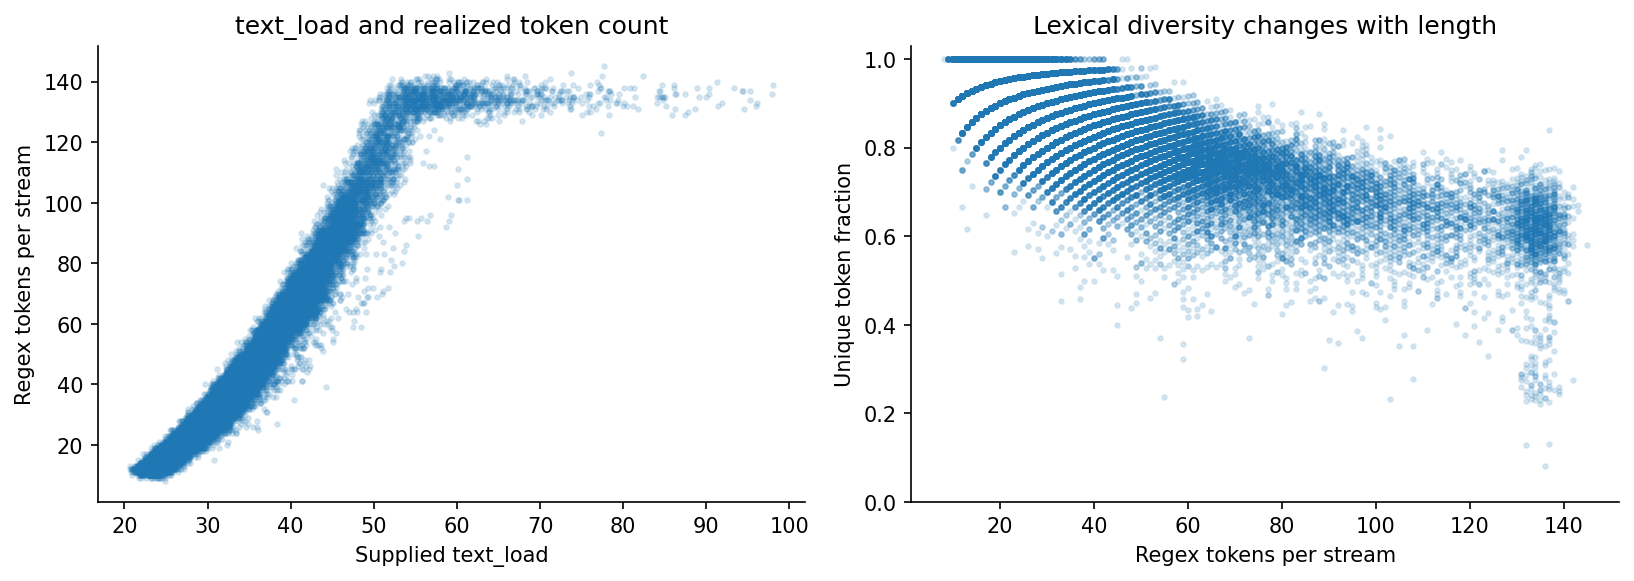

In [2]:
with redirect_stdout(StringIO()):
    text=run_text(ROOT, REPORT/'text')
display(pd.Series(text['availability'],name='availability'))
display(pd.DataFrame(text['text_diversity']['per_length_quintile'])[
    ['length_bin','n','low_diversity_n','high_diversity_n','artifact_rate_low','artifact_rate_high']])
show(Path('text/text_length_coherence.png'))

**Arah B melemah:** `text_load` sangat berkorelasi dengan jumlah token (Spearman 0,9829)
dan panjang karakter (0,9834), pada 47.204 stream tersedia. Ini konteks data yang berguna,
tetapi pertanyaan “apakah volume berhubungan dengan panjang” terlalu dekat dengan definisinya.
Arah A justru layak diteruskan karena outcome berbeda pada tingkat repetisi yang berbeda.

## Discovery C: informasi hilang dan kelengkapan

Hitung missing pada tujuh field: org, module, pattern, stream, trace, org_spread,
module_spread. `telemetry_flag` dikecualikan agar tidak mengambil inti EDA Rizky.
Missing stream mengikuti NaN atau blank setelah strip. Skor kelengkapan umum dan stream
kosong dibedakan; hubungan missingness dengan outcome tidak membuktikan MCAR/MAR atau sebab-akibat.

,missing_count,n,share,threat_mean,threat_median,threat_p10,threat_p90,threat_low_le5_share,threat_high_ge95_share,artifact_positive_share,cycles
0,0,26767,0.52891,49.85156,49.94510,9.50890,90.17986,0.05301,0.05193,0.35114,33
1,1,17692,0.34959,49.73532,49.31525,10.32646,89.76670,0.04720,0.04872,0.35118,33
2,2,5169,0.10214,51.06907,51.49420,11.35862,89.88288,0.04546,0.04972,0.32656,33
3,3,891,0.01761,53.68526,57.40840,10.56820,90.39940,0.04153,0.05163,0.28283,33
4,4,82,0.00162,66.09239,76.28115,23.34593,91.44724,0.01220,0.04878,0.18293,28
5,5,7,0.00014,75.25827,71.38780,62.73568,95.77784,0.00000,0.14286,0.42857,7


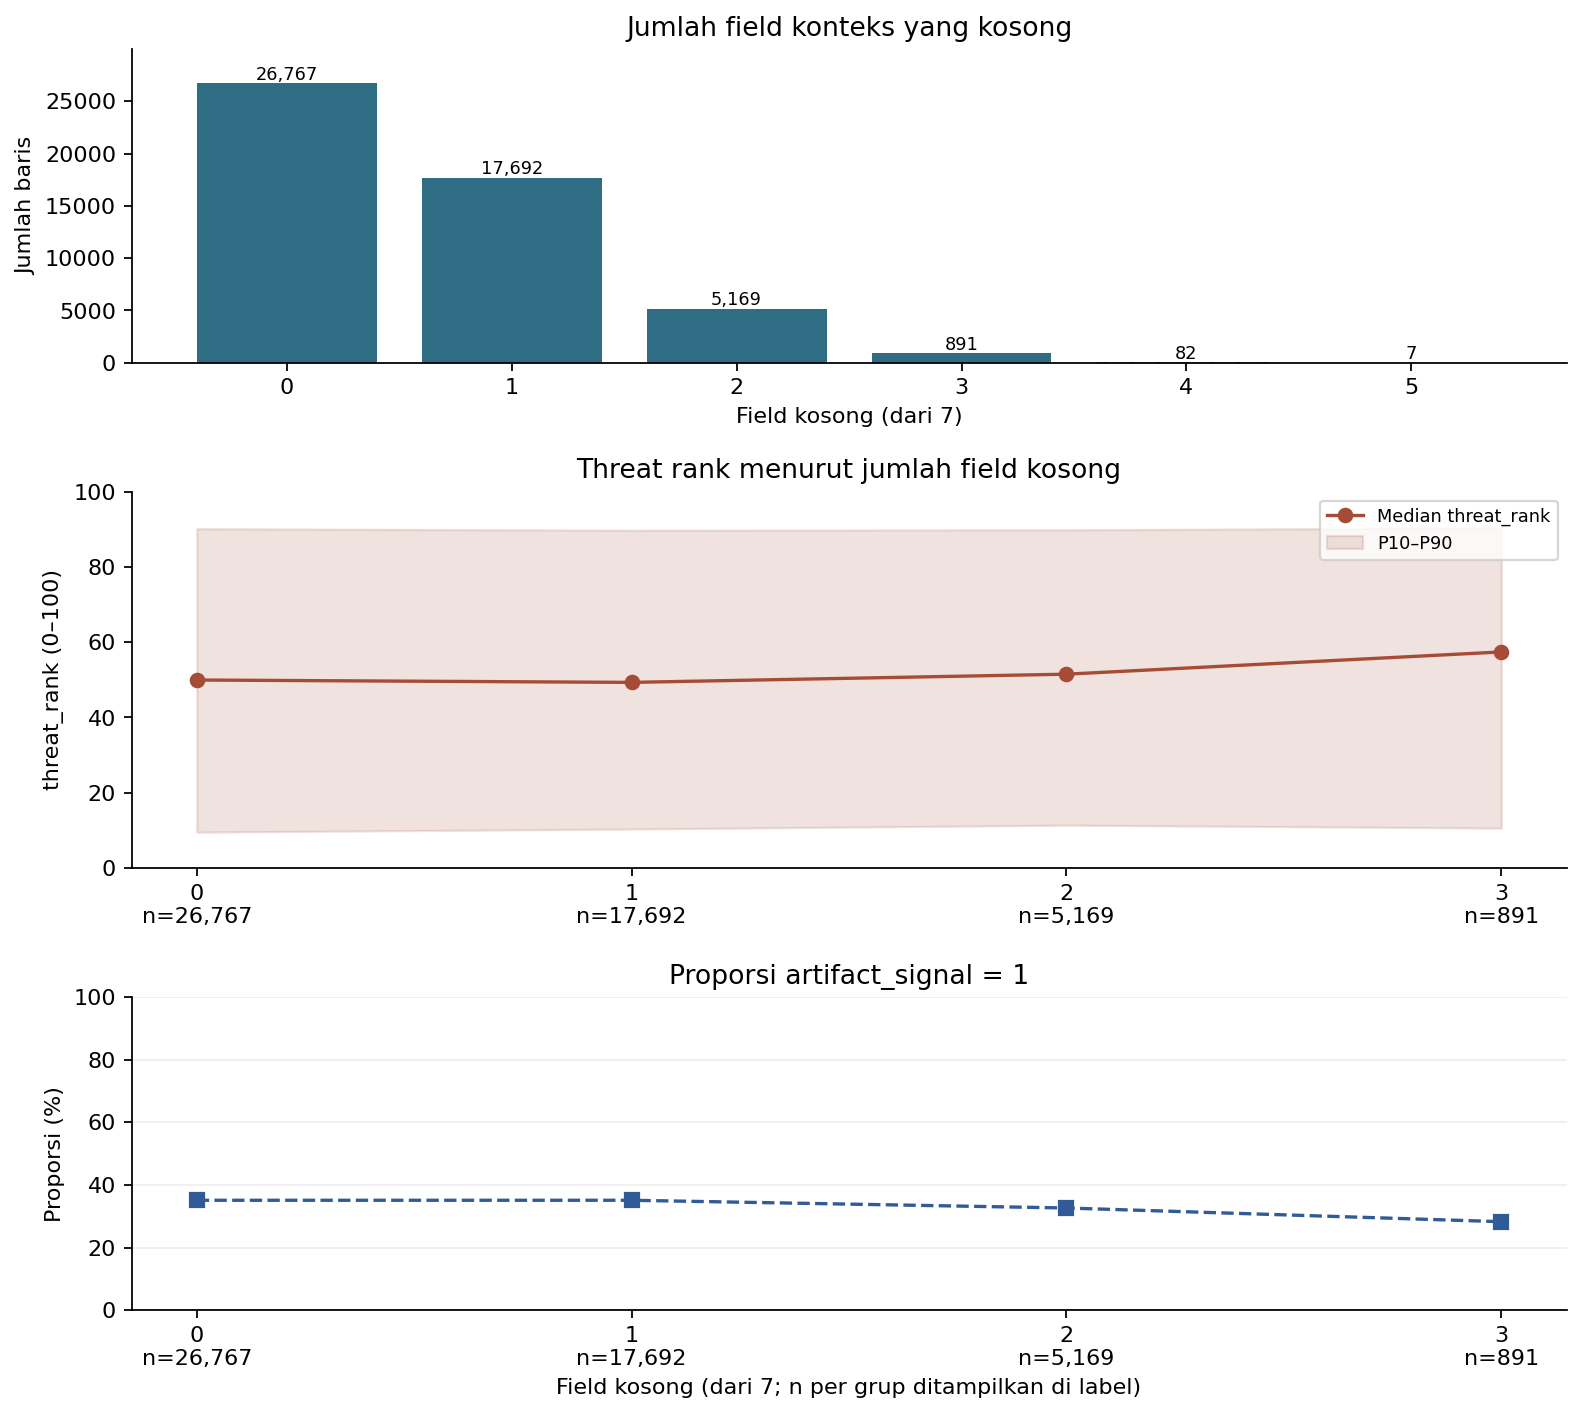

In [3]:
missing=run_missing(ROOT, REPORT/'missingness')
display(pd.read_csv(REPORT/'missingness/outcomes_by_missing_count.csv').head(6))
show(Path('missingness/figures/availability_count_and_outcomes.png'))

**Hasil negatif yang penting:** complete versus any-missing memberi gap mean rank hanya
+0,384 untuk any-missing, dengan arah campuran per-cycle; prevalence artifact 35,11% versus
34,27%. Kelompok dengan 4–5 missing sangat kecil. Skor completeness umum bukan kandidat kuat.
Stream kosong tersendiri memberi pola lebih besar yang perlu diperiksa komposisinya, bukan
dijadikan bukti bahwa “semakin tidak lengkap semakin berbahaya”.

## Discovery D–E: kategori pola, organisasi, dan modul

Semua kode yang memenuhi dukungan 30/100/300 diperiksa; tidak memilih beberapa kategori
dengan mean paling ekstrem. Missing bukan “kode yang diketahui” dan dilaporkan terpisah.
Subtract mean outcome setiap cycle hanya menghasilkan outcome yang dicenter terhadap cycle;
itu bukan standardisasi penuh komposisi kategori atau partial η² regresi multivariabel.

,field,minimum n,known codes,coverage
0,pattern_code,30,115,0.80217
1,pattern_code,100,68,0.75022
2,pattern_code,300,28,0.61212
3,org_code,30,165,0.50391
4,org_code,100,49,0.39417
5,org_code,300,24,0.31604
6,module_code,30,104,0.23587
7,module_code,100,20,0.16262
8,module_code,300,10,0.12674


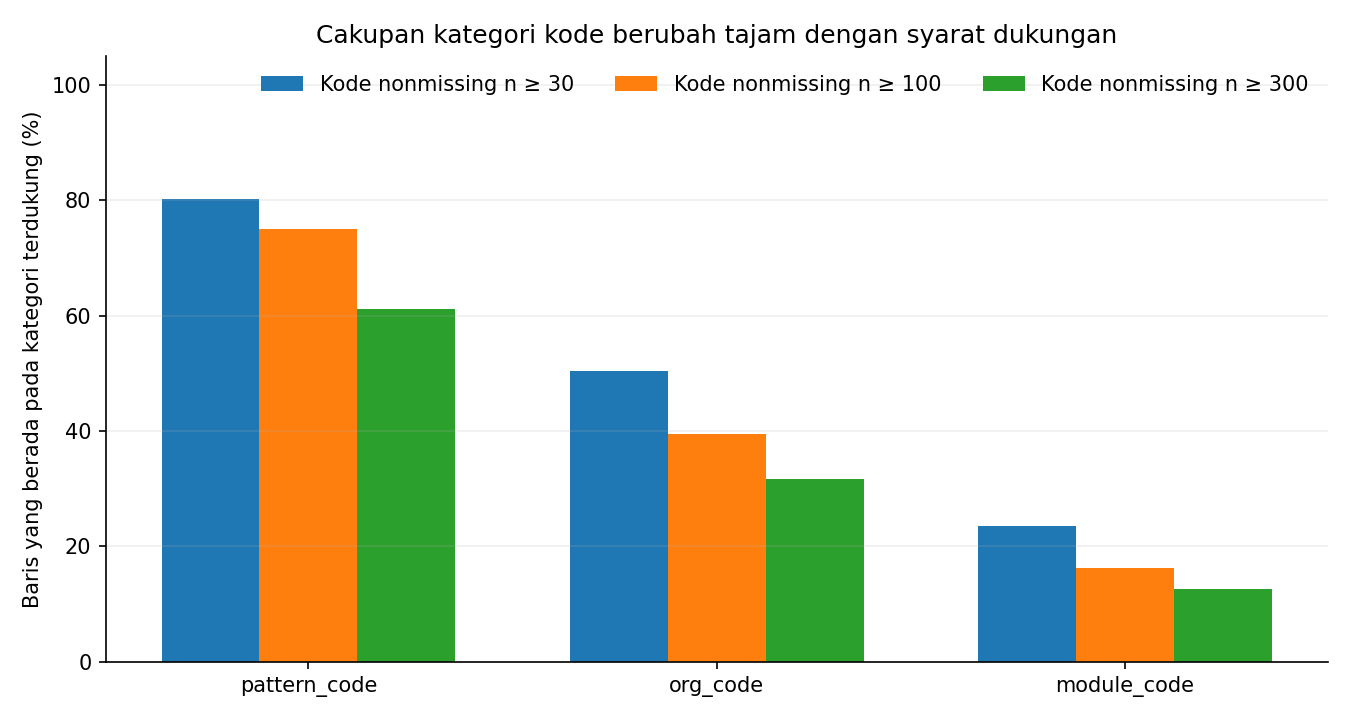

In [4]:
categories=run_categories(ROOT, REPORT/'categories')
support=[]
for column, item in categories['categories'].items():
    for minimum, value in item['support_counts'].items():
        support.append({'field':column,'minimum n':minimum,'known codes':value['nonmissing_categories'],
                        'coverage':value['nonmissing_category_row_coverage']})
display(pd.DataFrame(support))
show(Path('categories/figures/category_code_support_coverage.png'))

**D didukung data tetapi kurang mudah ditafsirkan:** 115 pattern codes dengan n≥30
mencakup 80,2% Train; heterogenitas outcome tetap terlihat pada beberapa support cutoffs.
Namun kode anonim tidak menjelaskan keluarga kerentanan secara domain, dan cycle-centering
belum menyingkirkan composition confounding. D tidak masuk tiga shortlist utama.
**E dieliminasi:** org/module sangat jarang, median ukuran kategori 1; coverage known-code
n≥30 hanya 50,4%/23,6%. Rentang mean ekstrem tidak cukup menjadi insight.

## Discovery F: apakah kedua outcome selalu sejalan?

Dua Train telah diverifikasi mempunyai ID dan seluruh fitur bersama yang identik.
Saya menggabungkan **dua label yang teramati** untuk EDA deskriptif, tidak menjadikan
target suatu task sebagai fitur task lain. Label `artifact_signal=0` berarti indikasi
artefak tidak teramati, bukan bukti artefak tidak ada. Rank adalah skor prioritas 0–100,
bukan probabilitas insiden. Geometri percentile per-cycle merupakan pola teramati;
formula pembentukan label belum diketahui.

F target concordance: 50608 rows; 24.4519 mean difference; 39.78 % high-rank without observed artifact


,artifact_signal,n,mean,median,sd,p10,p25,p75,p90
0,0,33038,41.5434,38.5657,27.5319,6.5704,16.9239,64.3495,81.4497
1,1,17570,65.9953,69.6602,24.1800,31.2174,46.1355,87.9665,95.8259


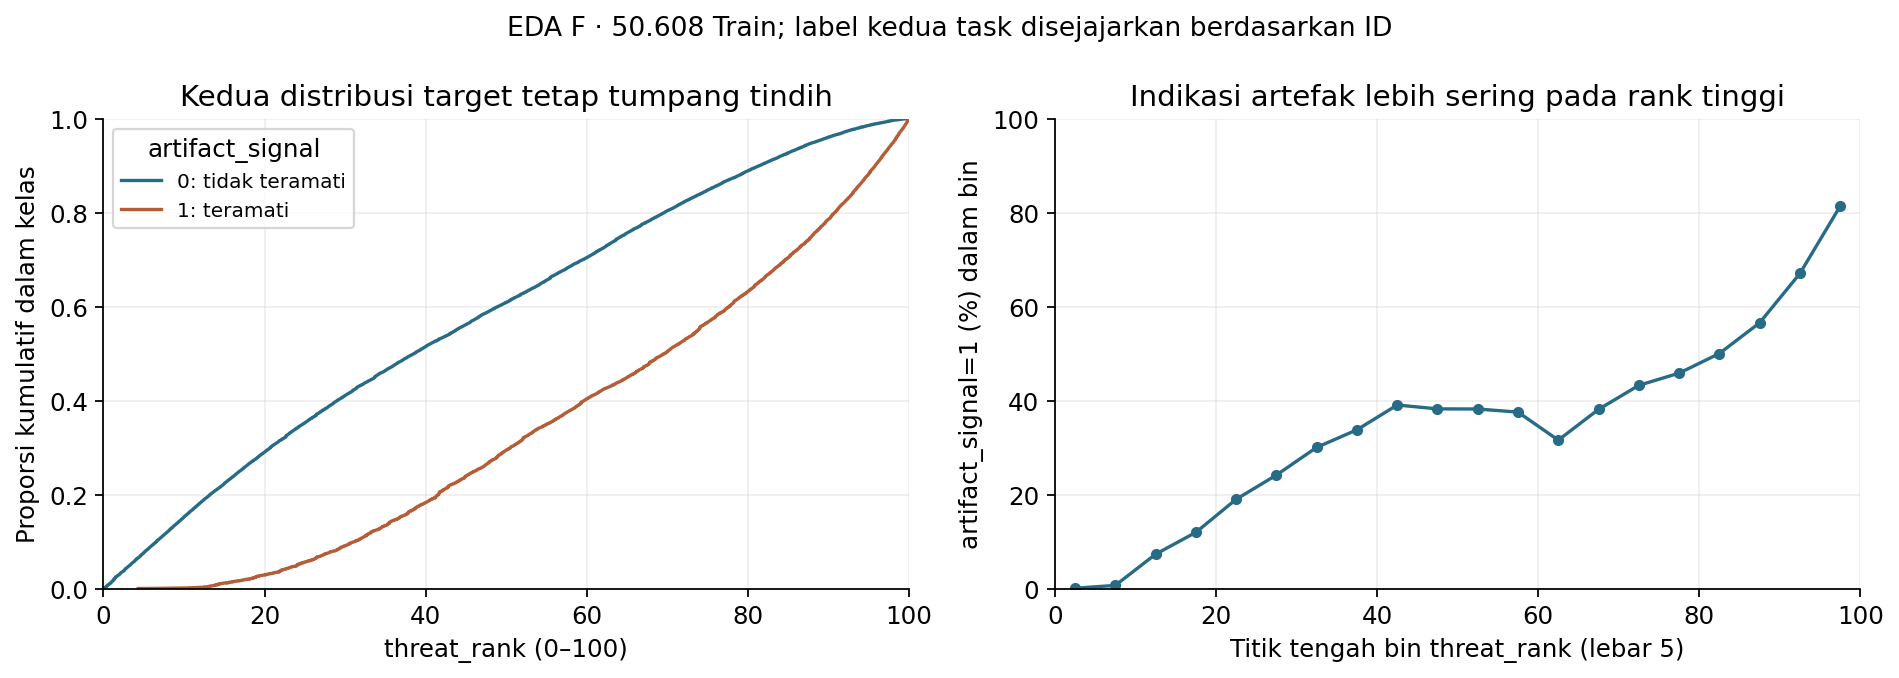

,ID,arah,bukti,keputusan
0,A,Keragaman token pada panjang sama,Gap artifact tertimbang 14.20 pp; 64/71 strata searah,Shortlist; kandidat utama untuk review
1,B,text_load versus panjang stream aktual,Spearman text_load–token count 0.9829,Tidak diteruskan sebagai pertanyaan utama; proxy panjang sangat kuat
2,C,Ketersediaan informasi / stream kosong,Gap rank pooled +8.118; setelah pembobotan volume sekitar −1 hingga 0,Shortlist stream availability; skor completeness umum ditolak
3,D,Heterogenitas keluarga pattern_code,115 kode n≥30 mencakup 80.2% Train,Bukti cukup; bukan 3 shortlist utama karena makna kode anonim
4,E,Konteks organisasi dan modul,Known-code coverage n≥30: org 50.4%; module 23.6%,"Dieliminasi: banyak singleton, coverage lemah, semantik anonim"
5,F,Keselarasan kedua outcome TP2,"5,029/12,643 rank≥75 berlabel0 (39.78%)","Shortlist; paling mudah dijelaskan, insight lebih deskriptif"


In [5]:
targets=run_targets(ROOT, REPORT/'targets')
display(pd.DataFrame(targets['groups']).round(4))
show(Path('targets/target_concordance.png'))
summary=build_views(ROOT)
display(pd.DataFrame(summary['screening'])[['ID','arah','bukti','keputusan']])

## Shortlist A: keragaman pada jumlah token sama

Di setiap jumlah token, gunakan **average percentile rank** keragaman; grup rendah
≤0,25 dan tinggi ≥0,75. Ties dipertahankan, tidak dipisahkan secara arbitrer. Panjang
harus memiliki n≥120 dan setiap tail n≥20; panjang yang tidak memiliki variasi/dukungan
dikeluarkan. Angka support 37.681 mencakup semua baris pada strata yang memenuhi syarat;
hanya **9.011 rendah + 9.354 tinggi** masuk kontras. Kedua grup memakai bobot strata
yang sama, n_panjang / total n_support, agar komposisi panjang dibandingkan setara.

,feature,supported_token_counts,support_rows,low_tail_compared_rows,high_tail_compared_rows,upper_vs_lower_diversity_artifact_delta,positive_token_count_strata
0,type_token_ratio,71,37681,9011,9354,0.14202,64
1,shannon_entropy,71,37681,9148,9736,0.10048,51
2,repeated_token_share,71,37681,9269,9612,0.14872,66


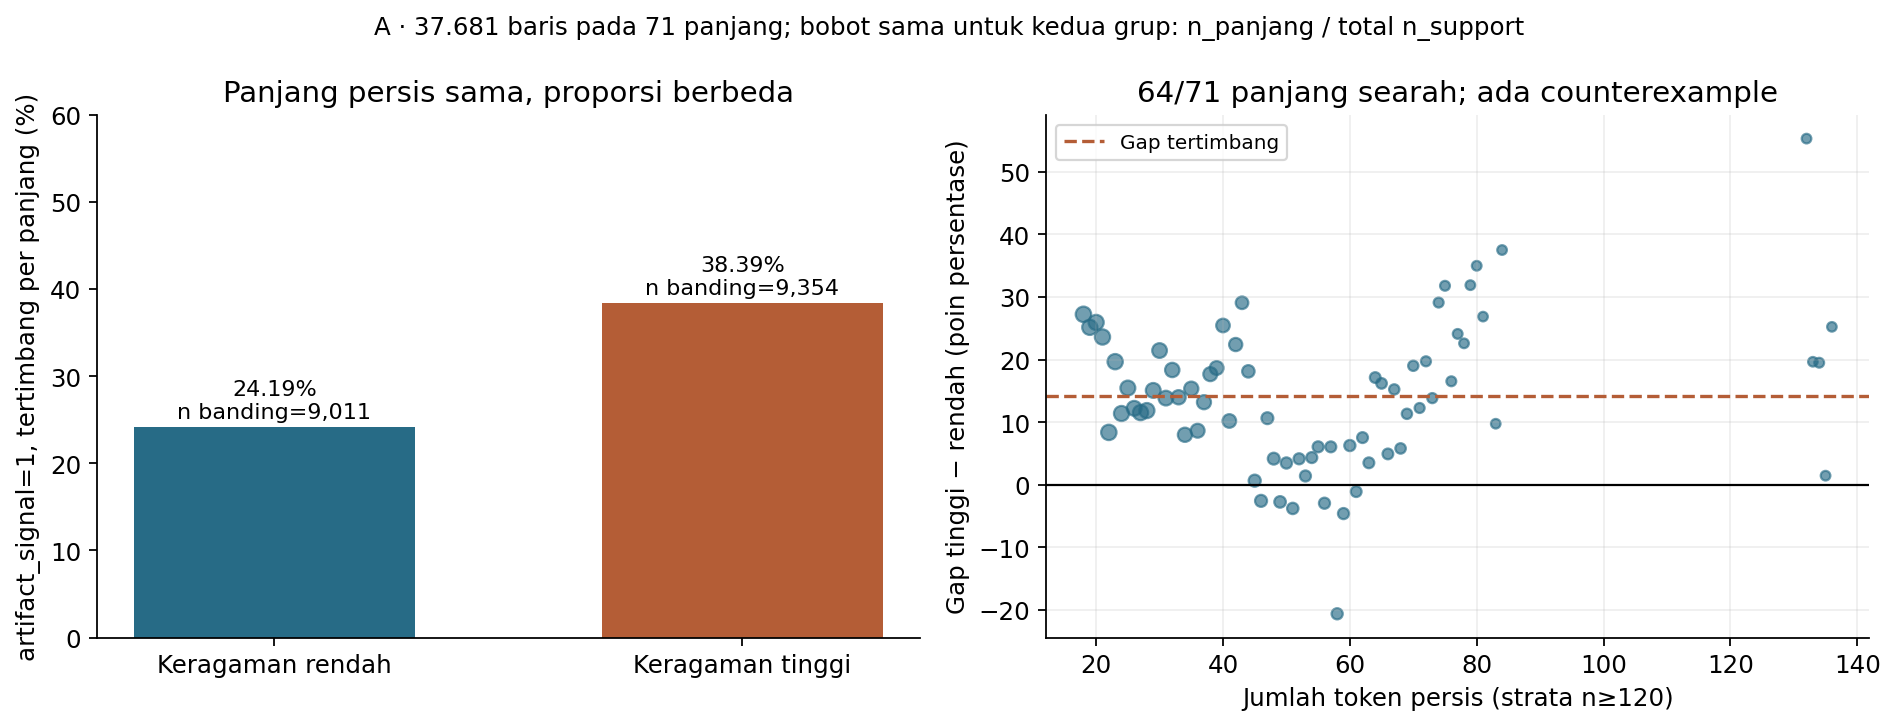

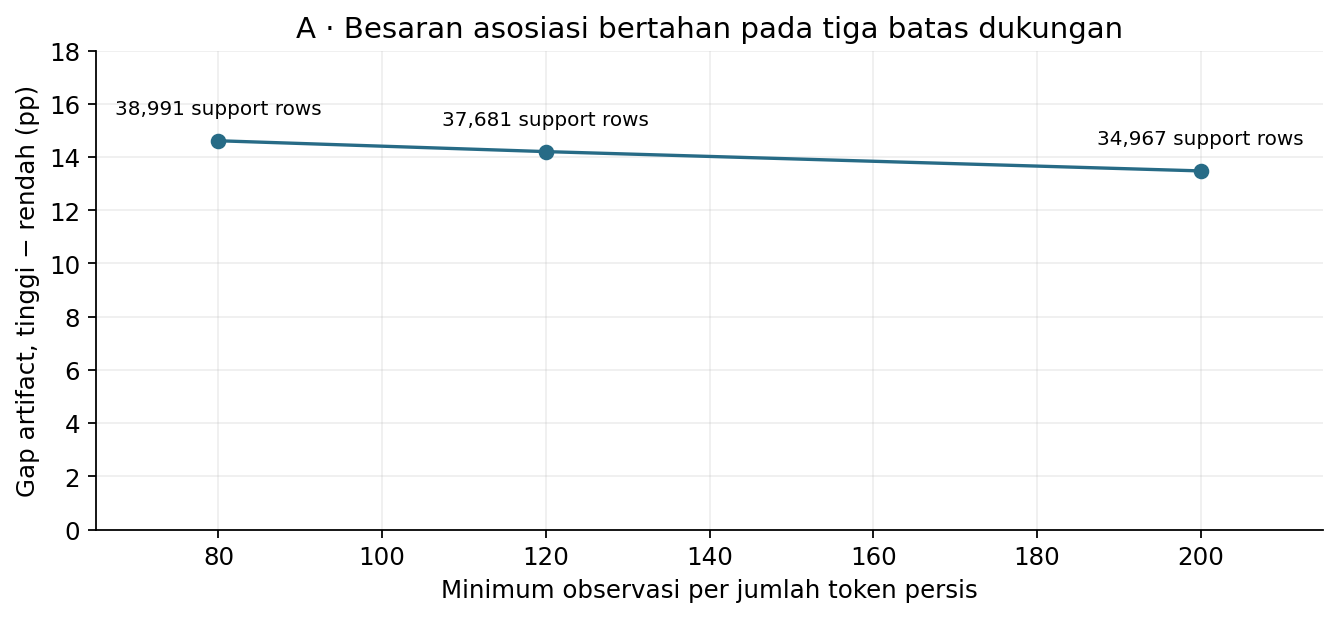

In [6]:
exact=text['text_diversity']['exact_token_count_sensitivity']
display(pd.DataFrame(exact['features'])[
    ['feature','supported_token_counts','support_rows','low_tail_compared_rows',
     'high_tail_compared_rows','upper_vs_lower_diversity_artifact_delta','positive_token_count_strata']])
show(Path('figures/A_exact_length_diversity.png'))
show(Path('figures/A_support_sensitivity.png'))

**Jawaban A:** prevalence artifact tertimbang 24,19%→38,39%, selisih **14,20 poin
persentase**. Pooled prevalence tail mentah 24,35%→38,83% adalah estimand berbeda;
jangan mencampur angka mentah dengan bobot common-length. Arah positif pada 64/71
panjang, bukan seluruh panjang: efek per panjang berkisar −20,59 sampai +55,31 pp.
Support mencakup 79,83% stream-present atau 74,46% semua Train; bukan semua data.

Dengan n minimum 80/120/200, gap tertimbang +14,61/+14,20/+13,48 pp. Entropy dan inverse
repeat-share memberi +10,05/+14,87 pp; ketiganya saling terkait, bukan replikasi independen.
Pada broad-length-bin comparison, arah positif terlihat pada 30/33 cycle. Tetapi
exact length×cycle hanya cukup pada 5 cycle (gate lebih longgar: n≥60/panjang dan ≥10/tail),
sehingga tidak ada klaim kontrol panjang
dan waktu sekaligus untuk seluruh Train. Resampling cycle mengasumsikan exchangeability,
tidak menangani serial dependence, dan bukan confidence interval konfirmatori.
Threat-rank tidak mempunyai stabilitas arah yang sama; rekomendasi A difokuskan pada artifact.
Komposisi kategori/konteks lain tetap mungkin menjelaskan sebagian asosiasi.

## Shortlist C: gap missing-stream dan komposisi volume

Tanpa stream (3.404 baris), mean/median rank 57,605/61,302; dengan stream 49,487/49,152.
Gap pooled mean **+8,118** tidak hilang hanya dengan mengecek cycle: arah positif 32/33.
Namun 76,7% stream kosong terkumpul pada decile `text_load` terendah.
Berikut saya samakan distribusi bin volume melalui bobot share bin seluruh Train.
Ini perbandingan deskriptif yang kasar, bukan identifikasi pengaruh missing text.

,text_load_decile,lower_edge,upper_edge,total_n,stream_missing_n,stream_present_n,missing_share,threat_mean_delta_missing_minus_present,threat_median_delta_missing_minus_present,artifact_rate_delta_missing_minus_present
0,0,16.3429,24.2178,5061,2610,2451,0.51571,10.30496,18.54795,-0.13966
1,1,24.2188,26.1885,5061,112,4949,0.02213,-4.00141,-3.04710,0.00673
2,2,26.1886,27.9143,5061,71,4990,0.01403,0.11154,0.96375,0.07547
3,3,27.9147,29.6087,5060,95,4965,0.01877,-6.88583,-4.78370,-0.05466
4,4,29.6088,31.3103,5062,85,4977,0.01679,-2.75774,0.71520,0.05481
5,5,31.3107,33.0484,5060,89,4971,0.01759,-4.80771,-6.99170,-0.05956
6,6,33.0490,35.1742,5060,78,4982,0.01542,2.89876,2.88295,-0.00556
7,7,35.1744,38.0223,5061,93,4968,0.01838,-5.92792,-8.58840,-0.06977
8,8,38.0233,42.8750,5061,86,4975,0.01699,1.37936,1.36180,-0.07145
9,9,42.8760,98.0650,5061,85,4976,0.01680,0.81511,1.26415,0.03776


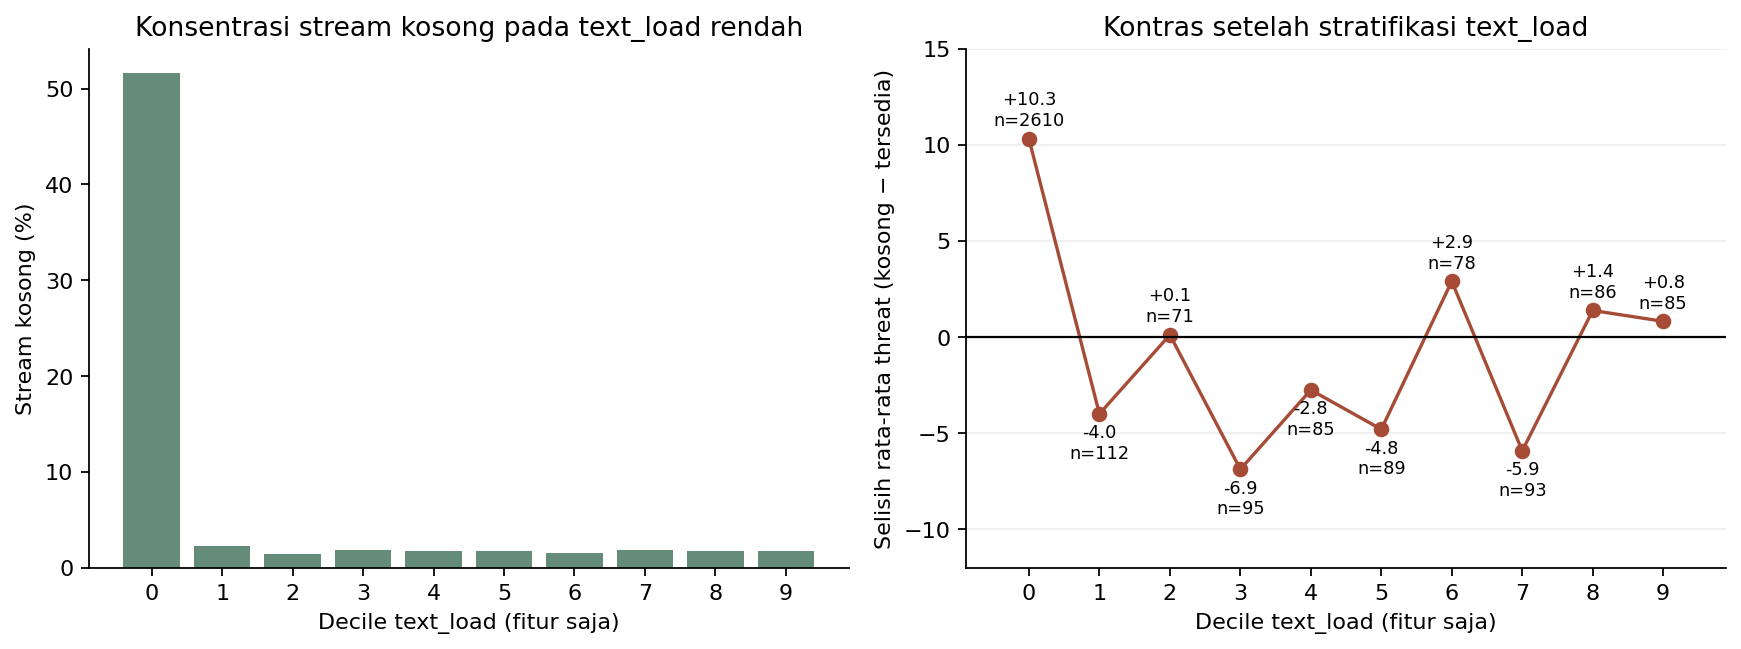

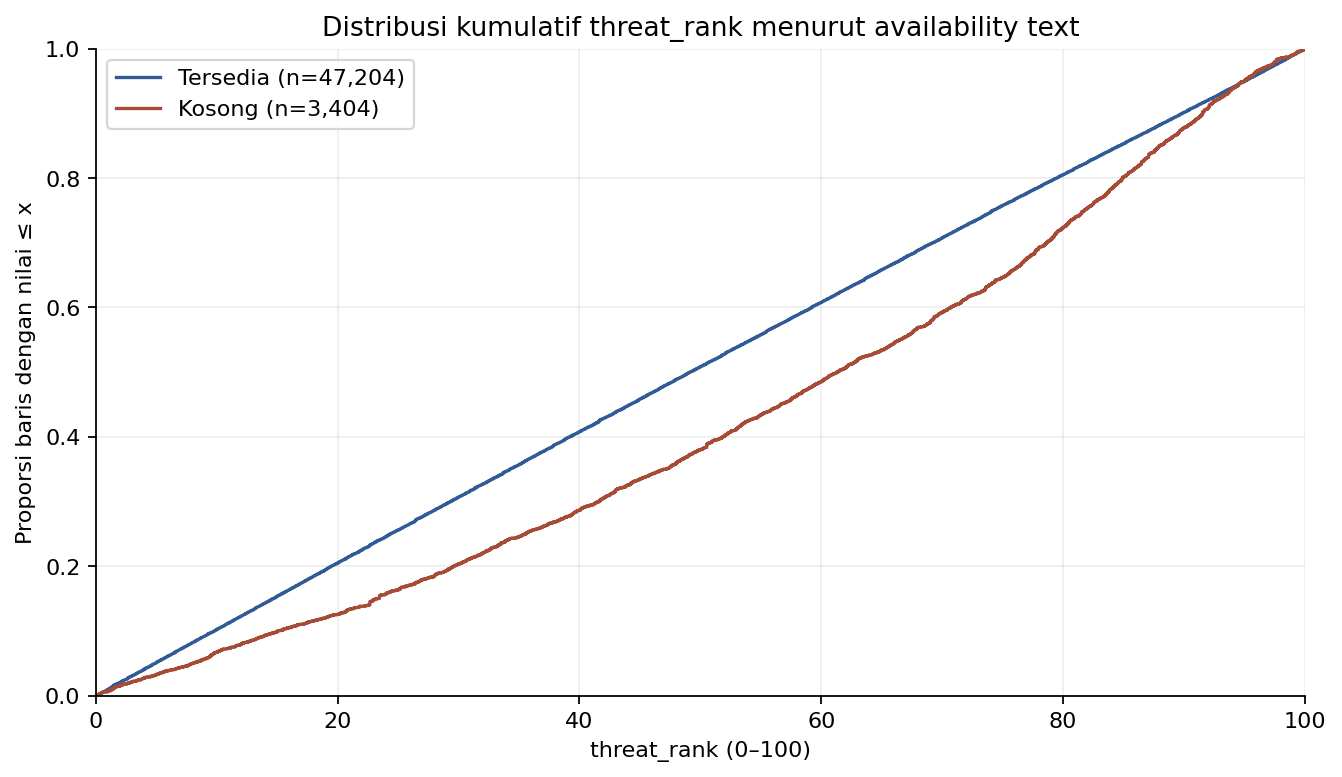

In [7]:
stream=missing['signal_stream_availability']
display(pd.read_csv(REPORT/'missingness/signal_stream_by_text_load_decile.csv'))
show(Path('missingness/figures/text_load_confounding_check.png'))
show(Path('missingness/figures/signal_stream_threat_ecdf.png'))

**Jawaban C:** gap besar marginal mengecil setelah komposisi volume dipertimbangkan:
+0,253/−0,887/−1,448 poin pada 5/10/20 quantile bins. Ini bukan pembalikan tanda yang
robust: tandanya sensitif jumlah bin, sedangkan penyusutan besarnya lebih konsisten.
Nominal support per bin 100% bukan matching sempurna: **906 baris kosong** mempunyai
text_load di bawah minimum stream-present. Effective n grup kosong setelah weighting
sekitar 953–1.049, lebih kecil daripada 3.404. Rentang volume yang sama menyisakan 2.498
missing rows; joint volume×pattern min20 hanya mencakup sekitar 13% semua Train.
Masih ada heterogenitas dan residual confounding. High-tail ≥95 hampir sama (~5,05%)
pada dua grup; gap mean bukan bukti seluruh distribusi naik atau tail lebih berbahaya.
Ini kandidat kuat untuk mengajarkan pentingnya komposisi, tetapi demo lebih rumit daripada A.

## Shortlist F: sejalan secara rata-rata, bukan identik

Mean rank label1 65,995 versus label0 41,543 (gap 24,452); arah gap positif pada
33/33 cycle. Point-biserial 0,403 mengukur asosiasi, bukan akurasi model atau kausalitas.
Pada batas deskriptif ≥75, **5.029/12.643 (39,78%)** berlabel0. Pada ≤25,
**987/12.638 (7,81%)** berlabel1. Batas-batas alternatif juga disimpan; cutoff ini
bukan keputusan keamanan atau risk threshold resmi.

,threshold,n_high,no_observed_artifact,share_within_high,share_of_all_records,n_low,observed_artifact,share_within_low
0,66.66667,16913.0,7537.0,0.44563,0.14893,—,—,—
1,75.00000,12643.0,5029.0,0.39777,0.09937,—,—,—
2,80.00000,10145.0,3675.0,0.36225,0.07262,—,—,—
3,90.00000,5068.0,1303.0,0.2571,0.02575,—,—,—
4,10.00000,—,—,—,0.00038,5058.0,19.0,0.00376
5,20.00000,—,—,—,0.00998,10100.0,505.0,0.05
6,25.00000,—,—,—,0.01950,12638.0,987.0,0.0781
7,33.33333,—,—,—,0.04211,16850.0,2131.0,0.12647


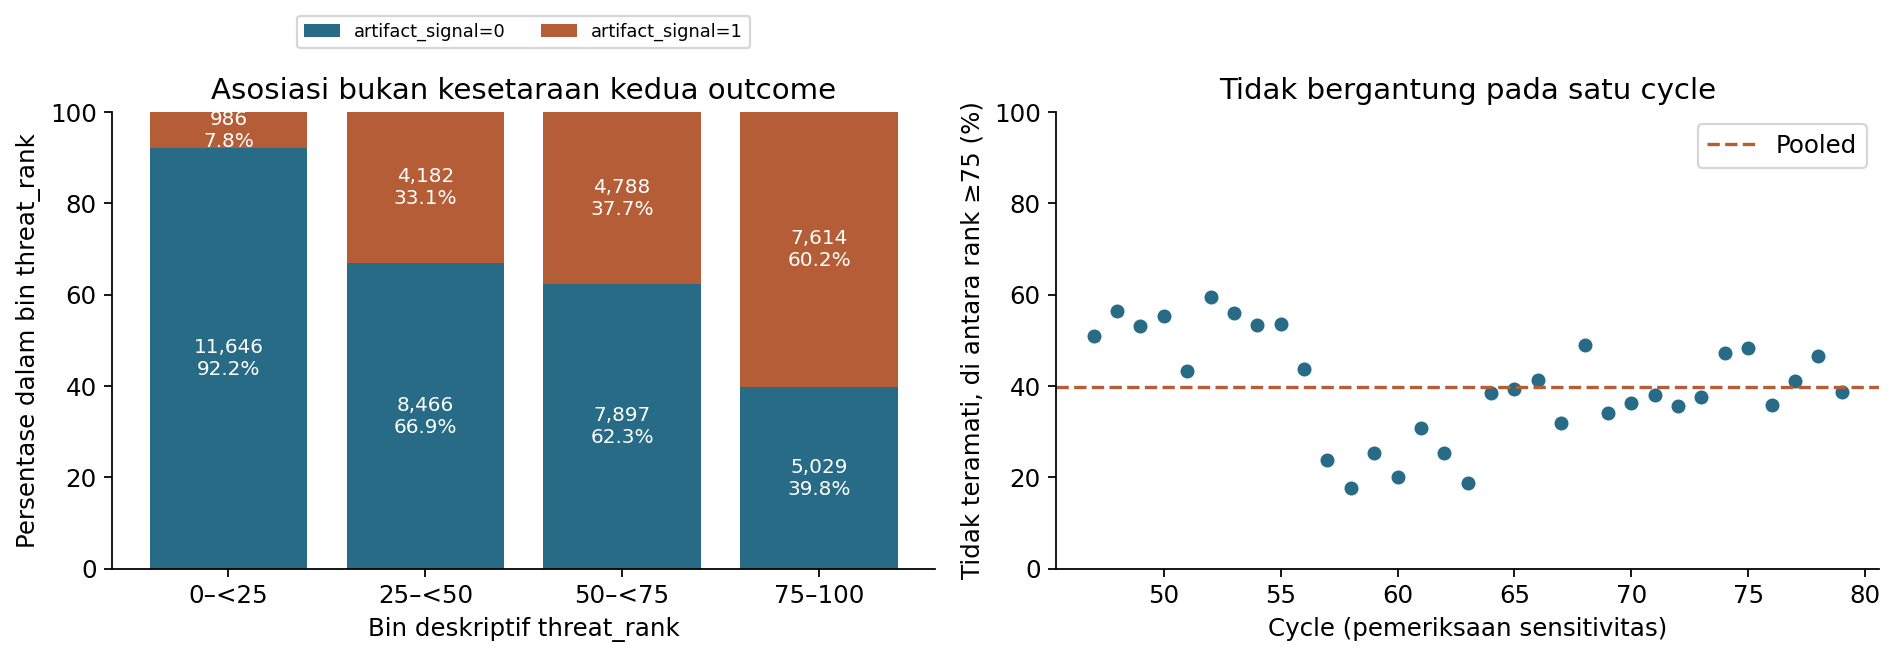

minimum_per_class                           30
groups                                      59
rows                                     44675
coverage                               0.88277
positive_difference_groups                  59
group_size_weighted_mean_gap          24.17019
support_uses_observed_class_counts        True
Name: pattern common support, dtype: object

In [8]:
display(pd.DataFrame(targets['threshold_sensitivity']).fillna('—'))
show(Path('targets/target_discordance.png'))
display(pd.Series(targets['pattern_supported'],name='pattern common support'))

Pola F tidak disebabkan satu cycle atau satu kategori: leave-one-cycle-out mean gap
24,121–24,735; 59 pattern groups dengan ≥30 baris tiap kelas juga searah, cakupan 88,28%.
Filter ini memakai **hitungan label per kelas**, bukan target-blind. Gap 24,170 pada
subset adalah group-size-weighted mean gap dalam satuan rank, bukan standardized effect
size. F paling sederhana dijelaskan, tetapi insight utamanya lebih deskriptif daripada A/C.
Tidak ada bukti arah sebab-akibat atau izin memakai label silang saat inference.

## Perbandingan, non-overlap, dan rekomendasi

Semua kandidat diperiksa terhadap empat topik: Rousan EF/impact→artifact; Abhi
scope_pressure→threat; Rizky telemetry×module_spread→artifact; Samuel lama
impact–threat antarcycle. Kesamaan target diizinkan; fitur utama dan fenomenanya berbeda.
Tidak ada kandidat yang memakai ketiga pasangan utama anggota lain sebagai fokus/kontrol.

In [9]:
display(pd.DataFrame(summary['overlap']))
display(pd.DataFrame(summary['comparison']))
print('REKOMENDASI UNTUK REVIEW:',summary['recommendation']['question'])
assert summary['recommendation']['official_question_changed'] is False
assert summary['recommendation']['final_notebook_preparation_resumed'] is False
assert exact['features'][0]['support_rows']==37681
assert targets['n']==50608 and missing['overall']['n']==50608
print('Semua analisis berasal dari dua Train resmi; tidak ada fit model, cache privat, atau upload.')

,ID,Rousan,Abhi,Rizky,Samuel lama,putusan
0,A,"Target sama, fitur utama teks; tanpa EF/impact",Bukan scope_pressure→threat; tidak memakai impact sebagai kontrol,Bukan telemetry/module_spread; keduanya bukan fitur utama/kontrol,Tidak meneliti impact–threat antarperiode; cycle hanya sensitivity check,Berbeda substantif; tidak mengubah pembagian resmi
1,B,"Target sama, fitur utama teks; tanpa EF/impact",Bukan scope_pressure→threat; tidak memakai impact sebagai kontrol,Bukan telemetry/module_spread; keduanya bukan fitur utama/kontrol,Tidak meneliti impact–threat antarperiode; cycle hanya sensitivity check,Berbeda substantif; tidak mengubah pembagian resmi
2,C,Bukan EF/impact→artifact,Bukan scope_pressure→threat; tidak memakai impact sebagai kontrol,Bukan telemetry/module_spread; keduanya bukan fitur utama/kontrol,Tidak meneliti impact–threat antarperiode; cycle hanya sensitivity check,Berbeda substantif; tidak mengubah pembagian resmi
3,D,Bukan EF/impact→artifact,Bukan scope_pressure→threat; tidak memakai impact sebagai kontrol,Bukan telemetry/module_spread; keduanya bukan fitur utama/kontrol,Tidak meneliti impact–threat antarperiode; cycle hanya sensitivity check,Berbeda substantif; tidak mengubah pembagian resmi
4,E,Bukan EF/impact→artifact,Bukan scope_pressure→threat; tidak memakai impact sebagai kontrol,Bukan telemetry×module_spread→artifact; module_code ≠ module_spread,Tidak meneliti impact–threat antarperiode; cycle hanya sensitivity check,Berbeda substantif; tidak mengubah pembagian resmi
5,F,Bukan EF/impact→artifact,Bukan scope_pressure→threat; tidak memakai impact sebagai kontrol,Bukan telemetry/module_spread; keduanya bukan fitur utama/kontrol,Tidak meneliti impact–threat antarperiode; cycle hanya sensitivity check,Berbeda substantif; tidak mengubah pembagian resmi


,kandidat,insight,dukungan,robustness,demo,kelemahan,relevansi
0,A · keragaman token,Asosiasi tetap pada panjang persis sama,"71 panjang; 37.681 support rows, 18.365 baris dibandingkan",80/120/200 minimum support; 3 ukuran keragaman; arah beragam,"Definisi sederhana, tetapi perlu menjelaskan ties dan pembobotan",Tidak memberi makna token; exact-length×cycle hanya 5 cycle,"Konteks Classification berbasis teks, tanpa klaim gain model disebabkan EDA"
1,C · stream availability,Gap marginal rank mengecil setelah komposisi volume,"3.404 kosong, 47.204 tersedia; 906 kosong di luar rentang tersedia","5/10/20 bin, common range, cycle, pattern, availability lain",Menarik untuk confounding; butuh menjelaskan common support,Tanda sesudah pembobotan sensitif bin; bukan penjelasan kausal,"Konteks informasi yang hilang, terpisah dari kesalahan model"
2,F · dua outcome,Asosiasi positif tidak berarti outcome dapat dipertukarkan,50.608 verified pairs; 5.029/12.643 rank tinggi berlabel0,"33 cycle, leave-one-cycle-out, ambang rank, common pattern",Paling intuitif: ECDF dan komposisi outcome,Asosiasi dasarnya relatif diharapkan; definisi high/low deskriptif,"Menjelaskan perbedaan dua task, bukan fitur silang untuk model"
3,EDA lama · impact–threat temporal,Marginal stabil menyembunyikan perubahan kondisional,"50.608 Train; common impact×EF 48.630 (96,09%)","33 cycle, periodisasi 2/3/4, composition, tails, cluster sensitivity","Lebih banyak konsep: korelasi, standardisasi, rank geometry",Perlu waktu menjelaskan nonmonotonisitas dan batas temporal,Kuat untuk generalisasi Regression; sudah selesai dan tetap valid


REKOMENDASI UNTUK REVIEW: Pada laporan dengan jumlah token yang sama, apakah keragaman token dalam signal_stream berkaitan dengan proporsi artifact_signal yang teramati?
Semua analisis berasal dari dua Train resmi; tidak ada fit model, cache privat, atau upload.


**Satu rekomendasi terbaik: A**, “Pada laporan dengan jumlah token yang sama, apakah
keragaman token dalam signal_stream berkaitan dengan proporsi artifact_signal yang teramati?”
Grafik utama: exact-length weighted prevalence dan seluruh 71 kontras panjang;
sensitivity support menyertai interpretasinya. Bukti tidak bergantung pada keberhasilan model teks.

**Apakah worth it mengganti?** Layak bila prioritas Samuel adalah pertanyaan yang lebih
fokus dan demo dengan dua konsep utama—repetisi teks dan proporsi outcome.
Saya tidak menyatakan A lebih unggul secara statistik universal: EDA lama sudah sangat
kuat, mempunyai common support 96,09%, periodisasi/EF/cycle robustness dan rank geometry
yang lebih luas. A mengorbankan coverage dan tidak menjawab temporal generalization.
Jika ingin mempertahankan pekerjaan yang sudah matang, EDA lama tetap layak.
Pemilihan resmi tetap menunggu review Samuel, bukan dilakukan notebook ini.

Penelitian ini belum membuktikan mekanisme kerentanan, kualitas bahasa, sebab-akibat,
formula generator target, private leaderboard performance atau kemampuan generalisasi.
Laporan lengkap: [Discovery](../../reports/eda_candidates/DISCOVERY_FINDINGS.md),
[Perbandingan](../../reports/eda_candidates/CANDIDATE_COMPARISON.md),
[Reproduksi/QA](../../reports/eda_candidates/REPRODUCIBILITY.md).
EDA lama dan seluruh checkpoint/model/submission dipertahankan utuh.